<img src="https://miro.medium.com/max/700/0*OC6s0YDZcQxACUAJ.jpg" width="600" height="600"/>

In this notebook, we will apply the PCA (Principal Component Analysis) and LGB (Light Gradient Boosting) techniques to the fault detection problem in the Tennessee Eastman Process benchmark. We will also evaluate the effect on the results of adding lag variables and filtering the measurement noise.



# Process description

<img src="https://raw.githubusercontent.com/gmxavier/TEP-meets-LSTM/master/tep_flowsheet.png" width="900" height="900"/>

### Manipulated Variables

Variable | Description
-------- | -----------
`XMV(1)`  | D Feed Flow (stream 2)            (Corrected Order)
`XMV(2)`  | E Feed Flow (stream 3)            (Corrected Order)
`XMV(3)`  | A Feed Flow (stream 1)            (Corrected Order)
`XMV(4)`  | A and C Feed Flow (stream 4)
`XMV(5)`  | Compressor Recycle Valve
`XMV(6)`  | Purge Valve (stream 9)
`XMV(7)`  | Separator Pot Liquid Flow (stream 10)
`XMV(8)`  | Stripper Liquid Product Flow (stream 11)
`XMV(9)`  | Stripper Steam Valve
`XMV(10)` | Reactor Cooling Water Flow
`XMV(11)` | Condenser Cooling Water Flow
`XMV(12)` | Agitator Speed

### Continuous Process Measurements

Variable | Description | unit
-------- | ----------- | ----
`XMEAS(1)`  | A Feed  (stream 1)                  | kscmh
`XMEAS(2)`  | D Feed  (stream 2)                  | kg/hr
`XMEAS(3)`  | E Feed  (stream 3)                  | kg/hr
`XMEAS(4)`  | A and C Feed  (stream 4)            | kscmh
`XMEAS(5)`  | Recycle Flow  (stream 8)            | kscmh
`XMEAS(6)`  | Reactor Feed Rate  (stream 6)       | kscmh
`XMEAS(7)`  | Reactor Pressure                    | kPa gauge
`XMEAS(8)`  | Reactor Level                       | %
`XMEAS(9)`  | Reactor Temperature                 | Deg C
`XMEAS(10)` | Purge Rate (stream 9)               | kscmh
`XMEAS(11)` | Product Sep Temp                    | Deg C
`XMEAS(12)` | Product Sep Level                   | %
`XMEAS(13)` | Prod Sep Pressure                   | kPa gauge
`XMEAS(14)` | Prod Sep Underflow (stream 10)      | m3/hr
`XMEAS(15)` | Stripper Level                      | %
`XMEAS(16)` | Stripper Pressure                   | kPa gauge
`XMEAS(17)` | Stripper Underflow (stream 11)      | m3/hr
`XMEAS(18)` | Stripper Temperature                | Deg C
`XMEAS(19)` | Stripper Steam Flow                 | kg/hr
`XMEAS(20)` | Compressor Work                     | kW
`XMEAS(21)` | Reactor Cooling Water Outlet Temp   | Deg C
`XMEAS(22)` | Separator Cooling Water Outlet Temp | Deg C

### Manipulated Variables

Variable | Description
-------- | -----------
`XMV(1)`  | D Feed Flow (stream 2)            (Corrected Order)
`XMV(2)`  | E Feed Flow (stream 3)            (Corrected Order)
`XMV(3)`  | A Feed Flow (stream 1)            (Corrected Order)
`XMV(4)`  | A and C Feed Flow (stream 4)
`XMV(5)`  | Compressor Recycle Valve
`XMV(6)`  | Purge Valve (stream 9)
`XMV(7)`  | Separator Pot Liquid Flow (stream 10)
`XMV(8)`  | Stripper Liquid Product Flow (stream 11)
`XMV(9)`  | Stripper Steam Valve
`XMV(10)` | Reactor Cooling Water Flow
`XMV(11)` | Condenser Cooling Water Flow
`XMV(12)` | Agitator Speed

### Sampled Process Measurements

- Reactor Feed Analysis (Stream 6)
  > - Sampling Frequency = 0.1 hr
  > - Dead Time = 0.1 hr
  > - Mole %
  
Variable | Description
-------- | -----------
`XMEAS(23)` | Component A
`XMEAS(24)` | Component B
`XMEAS(25)` | Component C
`XMEAS(26)` | Component D
`XMEAS(27)` | Component E
`XMEAS(28)` | Component F

- Purge Gas Analysis (Stream 9)
  > - Sampling Frequency = 0.1 hr
  > - Dead Time = 0.1 hr
  > - Mole %

Variable | Description
-------- | -----------
`XMEAS(29)` | Component A
`XMEAS(30)` | Component B
`XMEAS(31)` | Component C
`XMEAS(32)` | Component D
`XMEAS(33)` | Component E
`XMEAS(34)` | Component F
`XMEAS(35)` | Component G
`XMEAS(36)` | Component H

- Product Analysis (Stream 11)
  > - Sampling Frequency = 0.25 hr
  > - Dead Time = 0.25 hr
  > - Mole %

Variable | Description
-------- | -----------
`XMEAS(37)` | Component D
`XMEAS(38)` | Component E
`XMEAS(39)` | Component F
`XMEAS(40)` | Component G
`XMEAS(41)` | Component H

### Process Disturbances

Variable | Description
-------- | -----------
`IDV(1)`  | A/C Feed Ratio, B Composition Constant (Stream 4)          Step
`IDV(2)`  | B Composition, A/C Ratio Constant (Stream 4)               Step
`IDV(3)`  | D Feed Temperature (Stream 2)                              Step
`IDV(4)`  | Reactor Cooling Water Inlet Temperature                    Step
`IDV(5)`  | Condenser Cooling Water Inlet Temperature                  Step
`IDV(6)`  | A Feed Loss (Stream 1)                                     Step
`IDV(7)`  | C Header Pressure Loss - Reduced Availability (Stream 4)   Step
`IDV(8)`  | A, B, C Feed Composition (Stream 4)            Random Variation
`IDV(9)`  | D Feed Temperature (Stream 2)                  Random Variation
`IDV(10)` | C Feed Temperature (Stream 4)                  Random Variation
`IDV(11)` | Reactor Cooling Water Inlet Temperature        Random Variation
`IDV(12)` | Condenser Cooling Water Inlet Temperature      Random Variation
`IDV(13)` | Reaction Kinetics                                    Slow Drift
`IDV(14)` | Reactor Cooling Water Valve                            Sticking
`IDV(15)` | Condenser Cooling Water Valve                          Sticking
`IDV(16)` | Unknown
`IDV(17)` | Unknown
`IDV(18)` | Unknown
`IDV(19)` | Unknown
`IDV(20)` | Unknown

In [1]:
!pip install pyreadr==v0.3.3

import pyreadr
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy.stats
import sklearn.decomposition
import sklearn.preprocessing
import lightgbm as lgb

     |████████████████████████████████| 390 kB 426 kB/s 
You should consider upgrading via the '/opt/conda/bin/python3.7 -m pip install --upgrade pip' command.


In [2]:
print(np.__version__)
print(pd.__version__)
print(matplotlib.__version__)
print(scipy.__version__)
print(sklearn.__version__)
print(lgb.__version__)

1.18.1
1.0.3
3.2.1
1.4.1
0.23.1
2.3.1


# Principal Component Analysis

The Principal Component Analysis (PCA) technique applies a linear transformation to generate an orthogonal set of linear combinations of the original variables, whose directions are called principal components, with the aim of selecting a subset of these variables that appropriately summarizes the data variability.

When PCA is applied to detect faults, the principal components are identified using the training data; the principal components found during the training are also expected to explain the variability of the test data. If this is not the case, the process is considered to be faulty.

In [3]:
class ModelPCA ():
    
    def spe (self, X, X_pred): 
        return np.sum((X-X_pred)**2, axis=1)
   
    def train(self, df_train, plot = False):
        
        self.mu_train = df_train.mean(axis=0)
        self.std_train = df_train.std(axis=0)

        self.m = sklearn.decomposition.PCA(n_components = 0.9)

        X_train = sklearn.preprocessing.scale(df_train)
        X_train_pred = self.m.inverse_transform(self.m.fit_transform(X_train))
        
        if plot:
            fig, ax = plt.subplots()
            xaxis = np.arange(len(self.m.explained_variance_ratio_))
            ax.bar(xaxis, self.m.explained_variance_ratio_)
            ax.plot(xaxis, np.cumsum(self.m.explained_variance_ratio_));
            ax.set_title('PCA - Explained variance');
        
        return self.spe(X_train, X_train_pred)
            
    def test(self, df_test, plot = False):
        
        X_test = np.array((df_test-self.mu_train)/self.std_train)
        X_test_pred = self.m.inverse_transform(self.m.transform(X_test))

        return self.spe(X_test, X_test_pred)

# Light Gradient Boosting

Light Gradient Boosting is a tree-based algorithm that groups simple decision tree models using the boosting strategy, in which trees are trained sequentially and each one tries to correct the error of the previous tree.

Here we will use a strategy proposed by [Sergei Averkiev](https://kaggle.com/averkij/anomaly-detection-methods), in which each feature is predicted using the remaining features as predictors. The fault is detected when the mean squared error of all predictions exceeds a certain limit.

In [4]:
# as proposed by Sergei Averkiev (kaggle.com/averkij/anomaly-detection-methods)

class ModelEnsembleRegressors():
    
    def __init__ (self, regressor, **kwargs):
        self.regressor = regressor
        self.kwargs = kwargs

    def spe(self, y, y_pred): 
        return (y-y_pred)**2
        
    def train(self, df_train, plot = False):

        self.mu_train = df_train.mean(axis=0)
        self.std_train = df_train.std(axis=0)
        
        self.models = {}
        spe_df = pd.DataFrame()
        
        cols_to_predict = df_train.columns
        
        i = 0
        
        self.to_predict_test = []
        
        if plot:
            n_rows = int(np.ceil(len(df_train.columns)/4))
            fig, ax = plt.subplots(n_rows,4,figsize=(30,4*n_rows))
        
        for col in df_train.columns:
            
            #print('training model for', col)
            model = self.regressor(**self.kwargs)
            tr_x = sklearn.preprocessing.scale(df_train.drop([col],axis=1))
            tr_y = sklearn.preprocessing.scale(df_train[col])
        
            model.fit(X=tr_x, y=tr_y)
            
            tr_y_pred = model.predict(X=tr_x)
            
            self.models[col] = model
                                    
            spe_df[col] = self.spe(tr_y, tr_y_pred)
            
            #if np.mean(spe_df[col])<0.5:
            #    self.to_predict_test.append(col)
            
            self.to_predict_test.append(col)
            
            if plot:
                ax.ravel()[i].plot(tr_y)
                ax.ravel()[i].plot(tr_y_pred, alpha=0.5)
                ax.ravel()[i].set_title(f'{col} - SPE = {np.mean(spe_df[col]):.2f}')
                
            i+=1
                        
        return np.mean(spe_df, axis=1)
    
    def test(self, df_test, plot = False):

        spe_df = pd.DataFrame()
        
        i = 0

        if plot:
            n_rows = int(np.ceil(len(df_train.columns)/4))
            fig, ax = plt.subplots(n_rows,4,figsize=(30,4*n_rows))
        
        for col in self.to_predict_test:
            ts_x = np.array((df_test.drop([col],axis=1)-self.mu_train.drop([col]))/self.std_train.drop([col]))
            ts_y = np.array((df_test[col]-self.mu_train[col])/self.std_train[col])
            ts_y_pred = self.models[col].predict(ts_x)
            spe_df[col] = self.spe(ts_y, ts_y_pred)
            
            if plot:
                ax.ravel()[i].plot(ts_y)
                ax.ravel()[i].plot(ts_y_pred, alpha=0.5)
                ax.ravel()[i].set_title(f'{col}/SPE = {np.mean(spe_df[col]):.2f}')
            
            i+=1
                
        return np.mean(spe_df, axis=1)

# Lag variables

Lag variables are columns added to the data set that include past points of the variables. With this transformation, each row contains the past of the variables. The representation can help to model dynamics, that is, when the past of the variables is important to understand the present.

In [5]:
def apply_lag (df, lag = 1):
       
    from statsmodels.tsa.tsatools import lagmat
    array_lagged = lagmat(df, maxlag=lag,
                          trim="forward", original='in')[lag:,:]  
    new_columns = []
    for l in range(lag):
        new_columns.append(df.columns+'_lag'+str(l+1))
    columns_lagged = df.columns.append(new_columns)
    index_lagged = df.index[lag:]
    df_lagged = pd.DataFrame(array_lagged, index=index_lagged,
                             columns=columns_lagged)
       
    return df_lagged  

# Noise filtering

The moving average filter is one of the simplest ways to decrease noise (unwanted variability) in a data set. It works by replacing individual points with averages calculated in data windows. 

There are several strategies for applying moving average filters. Here, we will replace each point with the average of a window of size $W$ which contains the point in question and $W-1$ previous points.

In [6]:
def filter_noise_ma (df, WS = 100,reduction = False):

    import copy
    
    new_df = copy.deepcopy(df)

    for column in df:
        new_df[column] = new_df[column].rolling(WS).mean()

    if reduction:
        return new_df.drop(df.index[:WS])[::WS]
    else:
        return new_df.drop(df.index[:WS])

# Importing and visualizing data

In [7]:
train_normal_path = '/kaggle/input/tennessee-eastman-process-simulation-dataset/TEP_FaultFree_Training.RData'
train_faulty_path = '/kaggle/input/tennessee-eastman-process-simulation-dataset/TEP_Faulty_Training.RData'

test_normal_path = '/kaggle/input/tennessee-eastman-process-simulation-dataset/TEP_FaultFree_Testing.RData'
test_faulty_path = '/kaggle/input/tennessee-eastman-process-simulation-dataset/TEP_Faulty_Testing.RData'

train_normal_complete = pyreadr.read_r(train_normal_path)['fault_free_training']
#train_faulty_complete = pyreadr.read_r(train_fault_path)['faulty_training']

#test_normal_complete = pyreadr.read_r(test_normal_path)['fault_free_testing']
test_faulty_complete = pyreadr.read_r(test_faulty_path)['faulty_testing']

## Visualizing training set

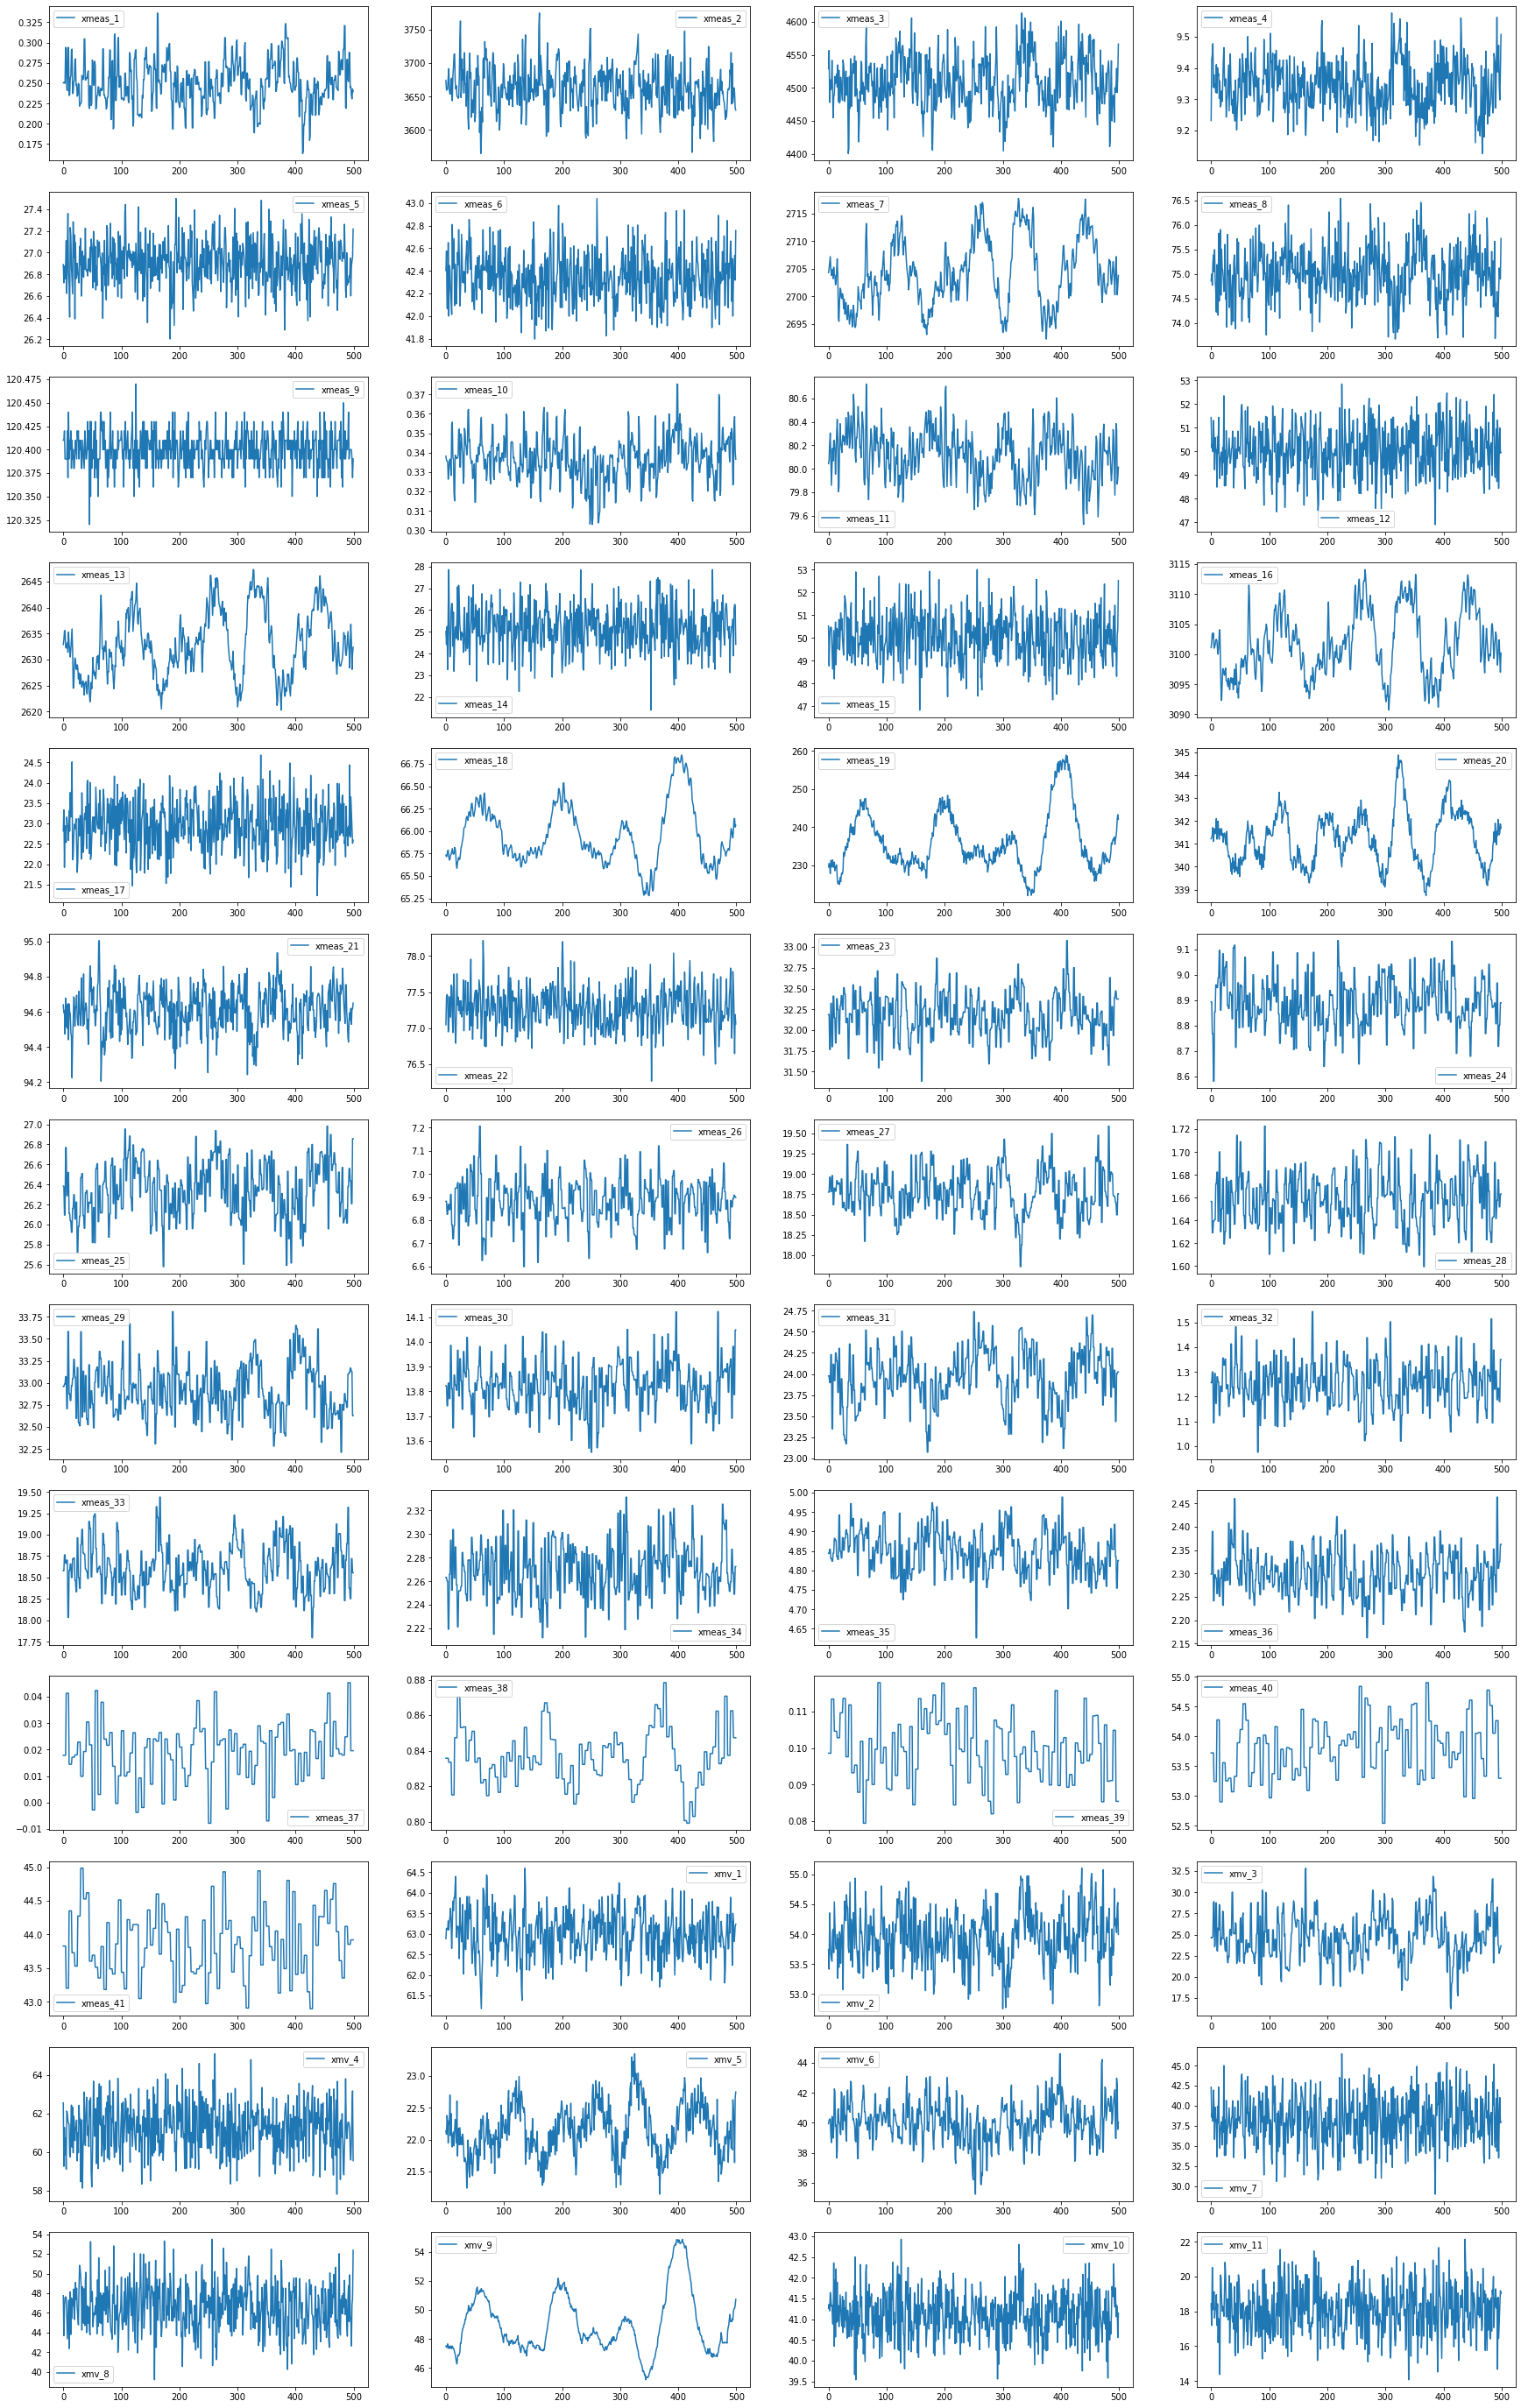

In [8]:
df_train = train_normal_complete[train_normal_complete.simulationRun==1].iloc[:,3:]

fig, ax = plt.subplots(13,4,figsize=(30,50))

for i in range(df_train.shape[1]):
    df_train.iloc[:,i].plot(ax=ax.ravel()[i]) 
    ax.ravel()[i].legend();

## Visualizing a faulty test set

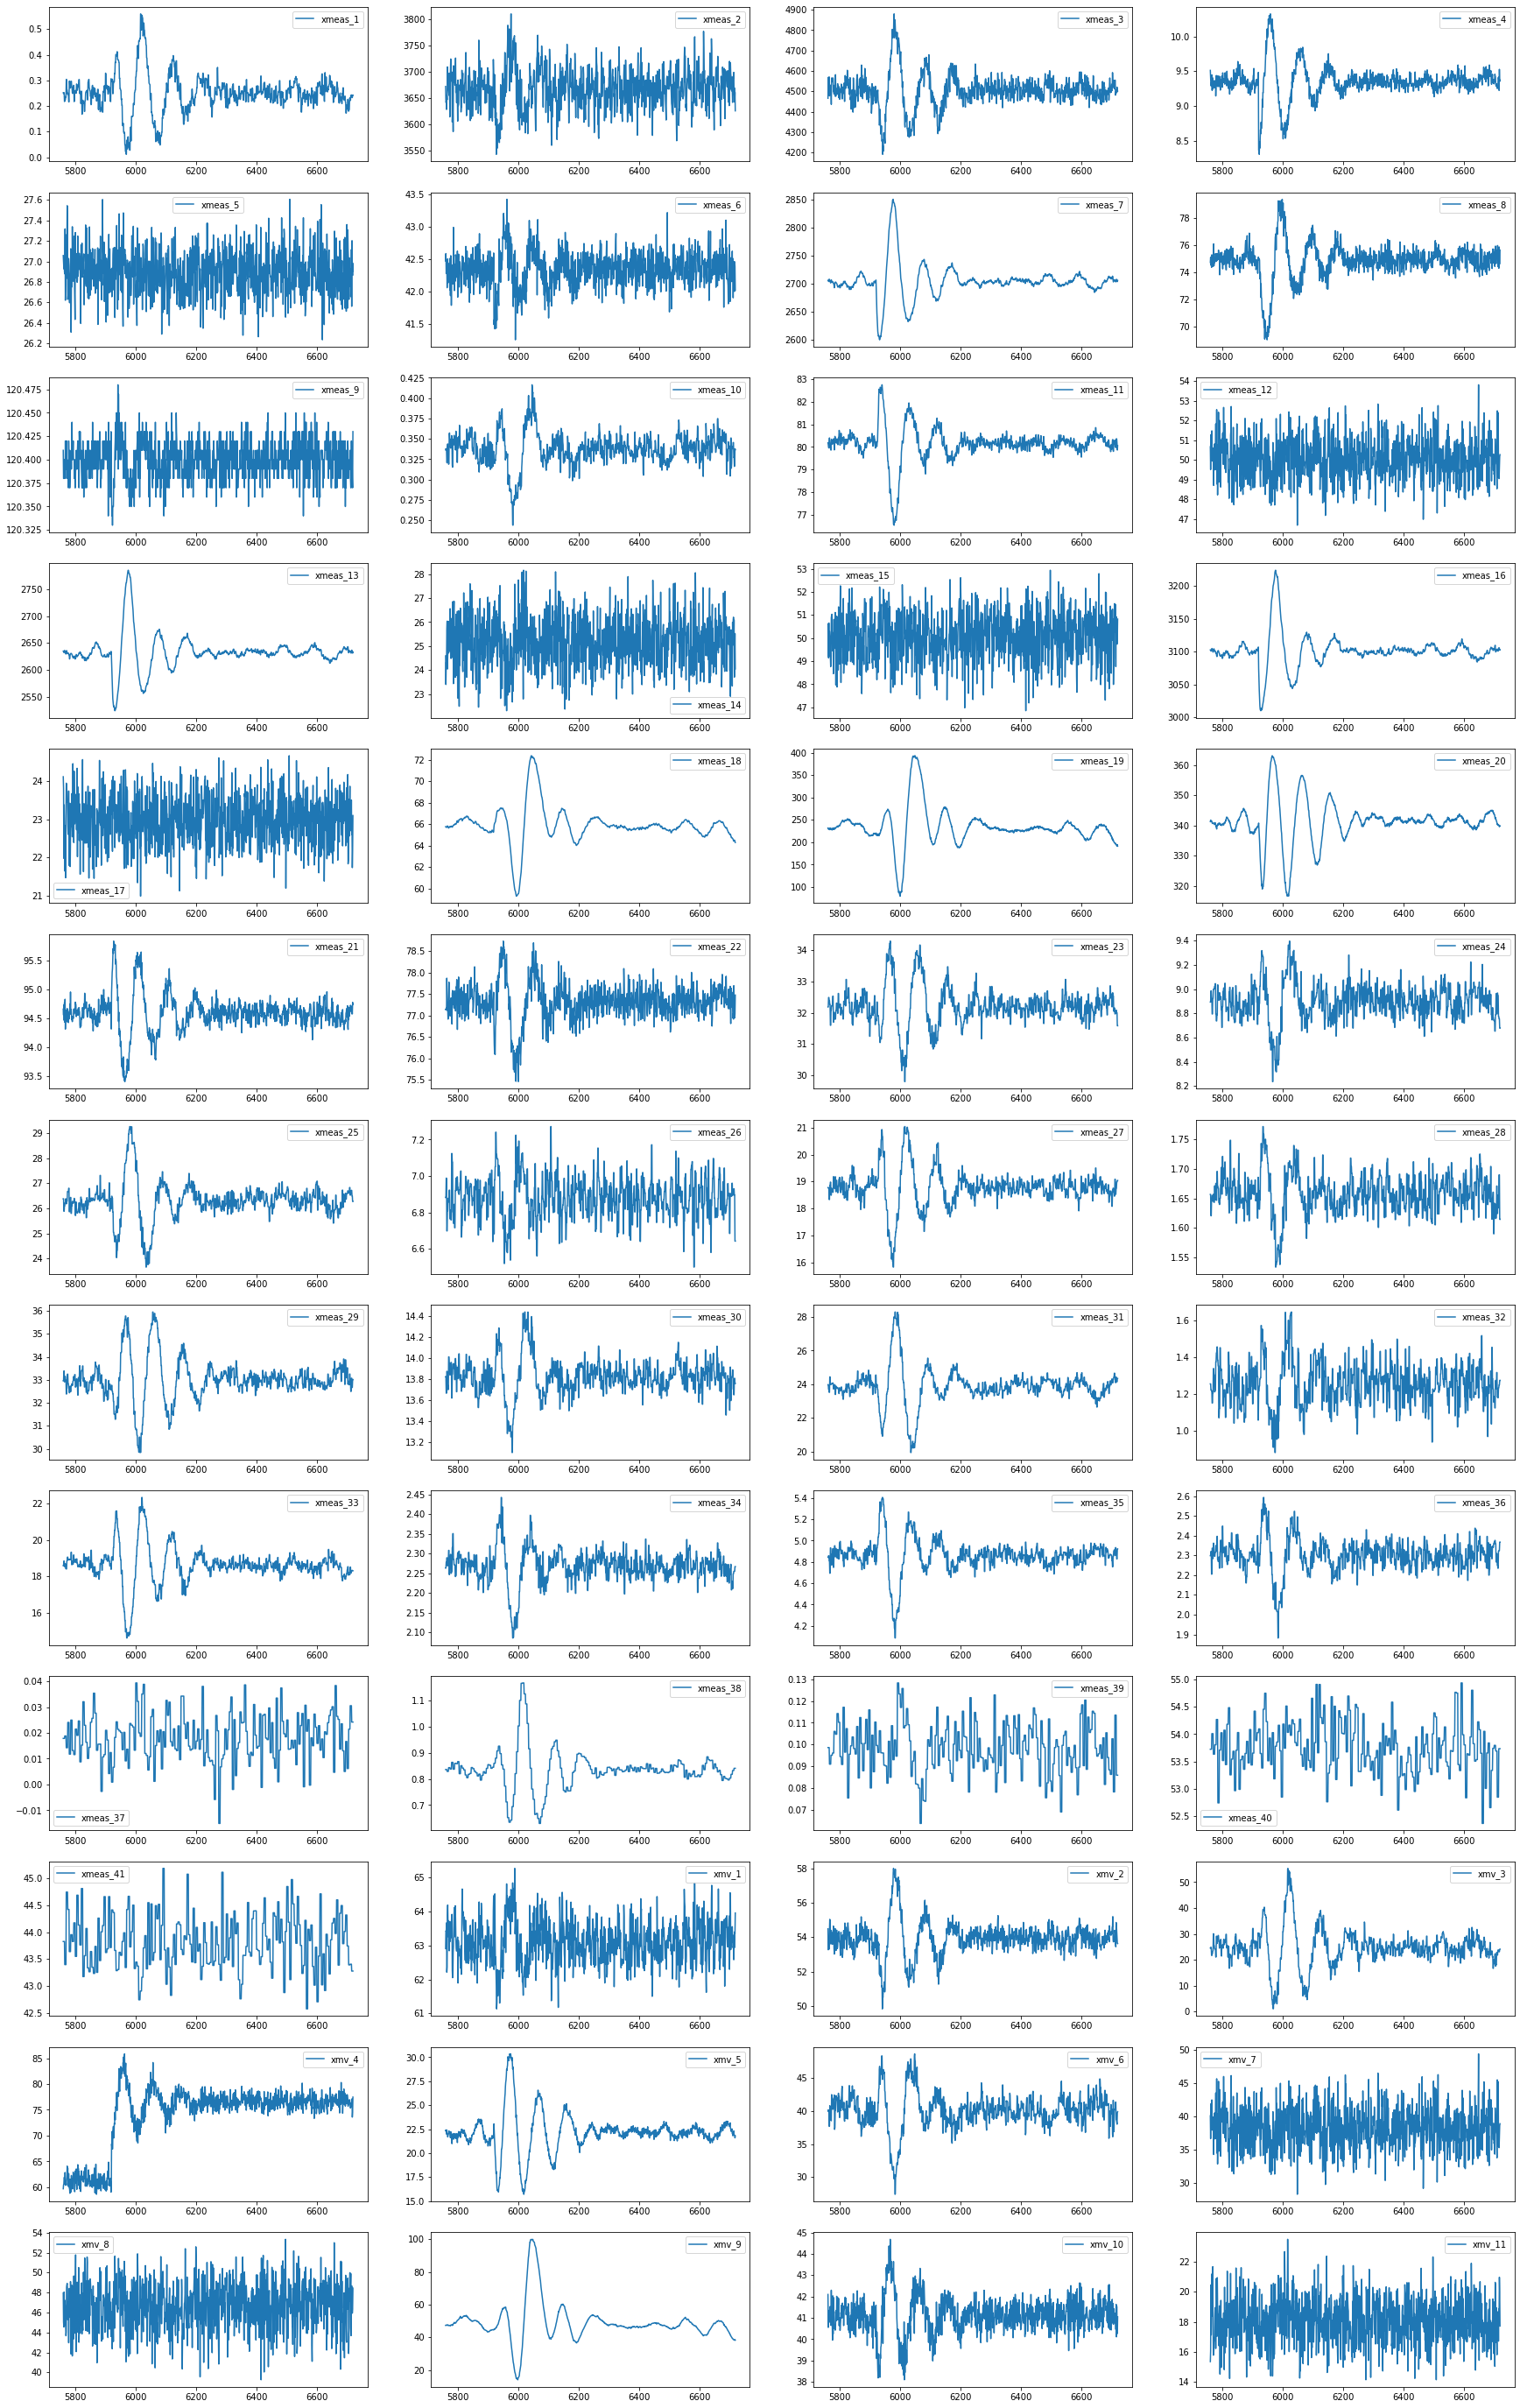

In [9]:
test_f1_run1 = test_faulty_complete[(test_faulty_complete.faultNumber==7) & (test_faulty_complete.simulationRun==1)].iloc[:,3:]

fig, ax = plt.subplots(13,4,figsize=(30,50))

for i in range(test_f1_run1.shape[1]):
    test_f1_run1.iloc[:,i].plot(ax=ax.ravel()[i]) 
    ax.ravel()[i].legend();

## Visualizing Spearman Correlations

Features that have strong correlations with others will be easier to model with LGB.

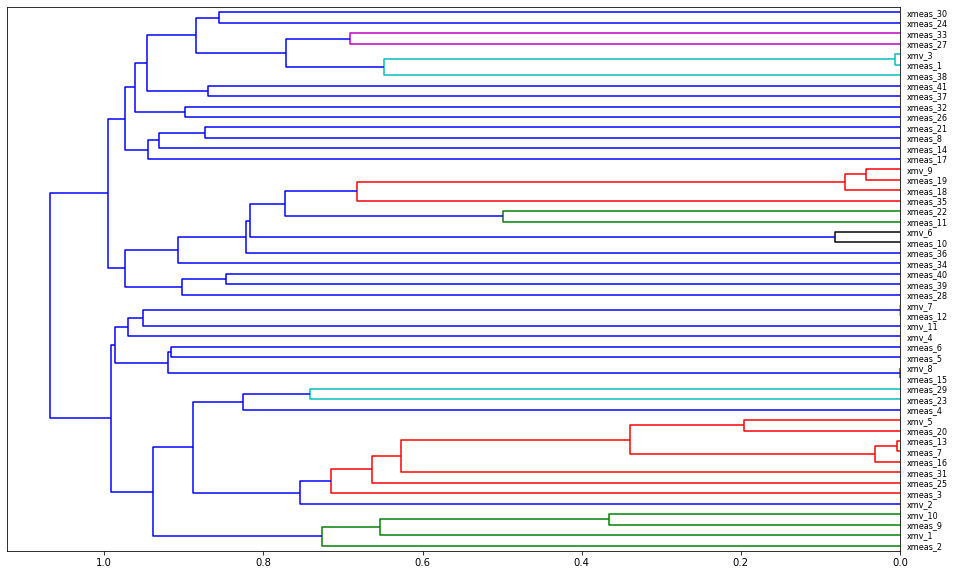

In [10]:
from scipy.cluster import hierarchy as hc
corr = np.round(scipy.stats.spearmanr(df_train).correlation, 4)
corr_condensed = hc.distance.squareform(1-corr)
z = hc.linkage(corr_condensed, method='average')
fig = plt.figure(figsize=(16,10))
dendrogram = hc.dendrogram(z, labels=df_train.columns, orientation='left', leaf_font_size=8)
plt.show()

# Training

In the following pictures we have:

* the SPE charts for the two models;
* the explained variance of PCA;
* the LGB predictions of each variable.

Validation and testing were calculated using normal data.

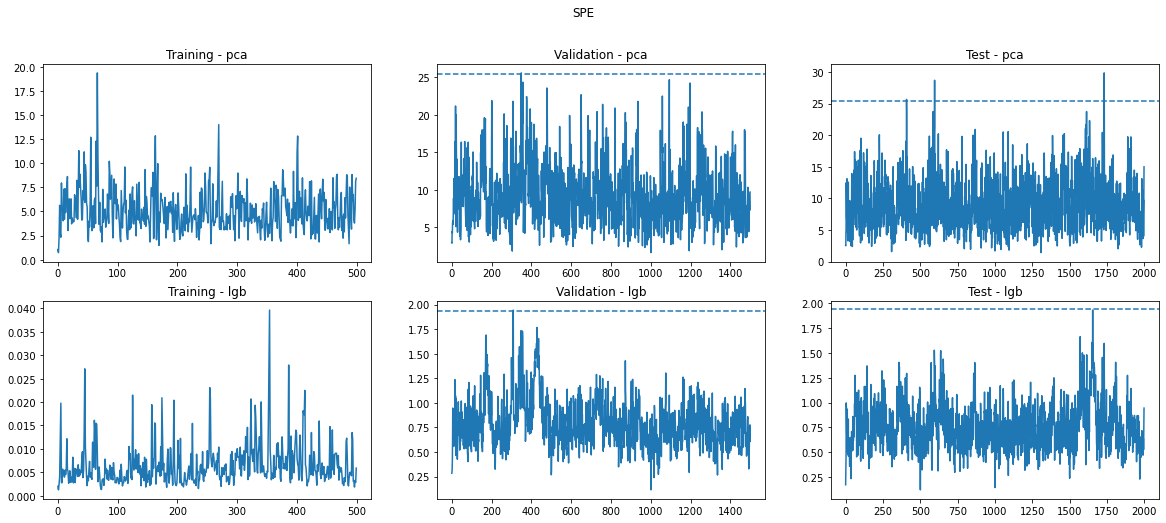

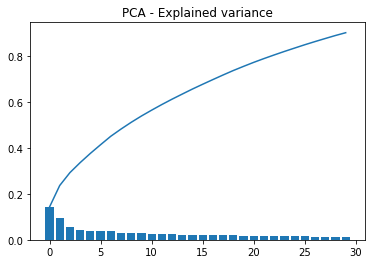

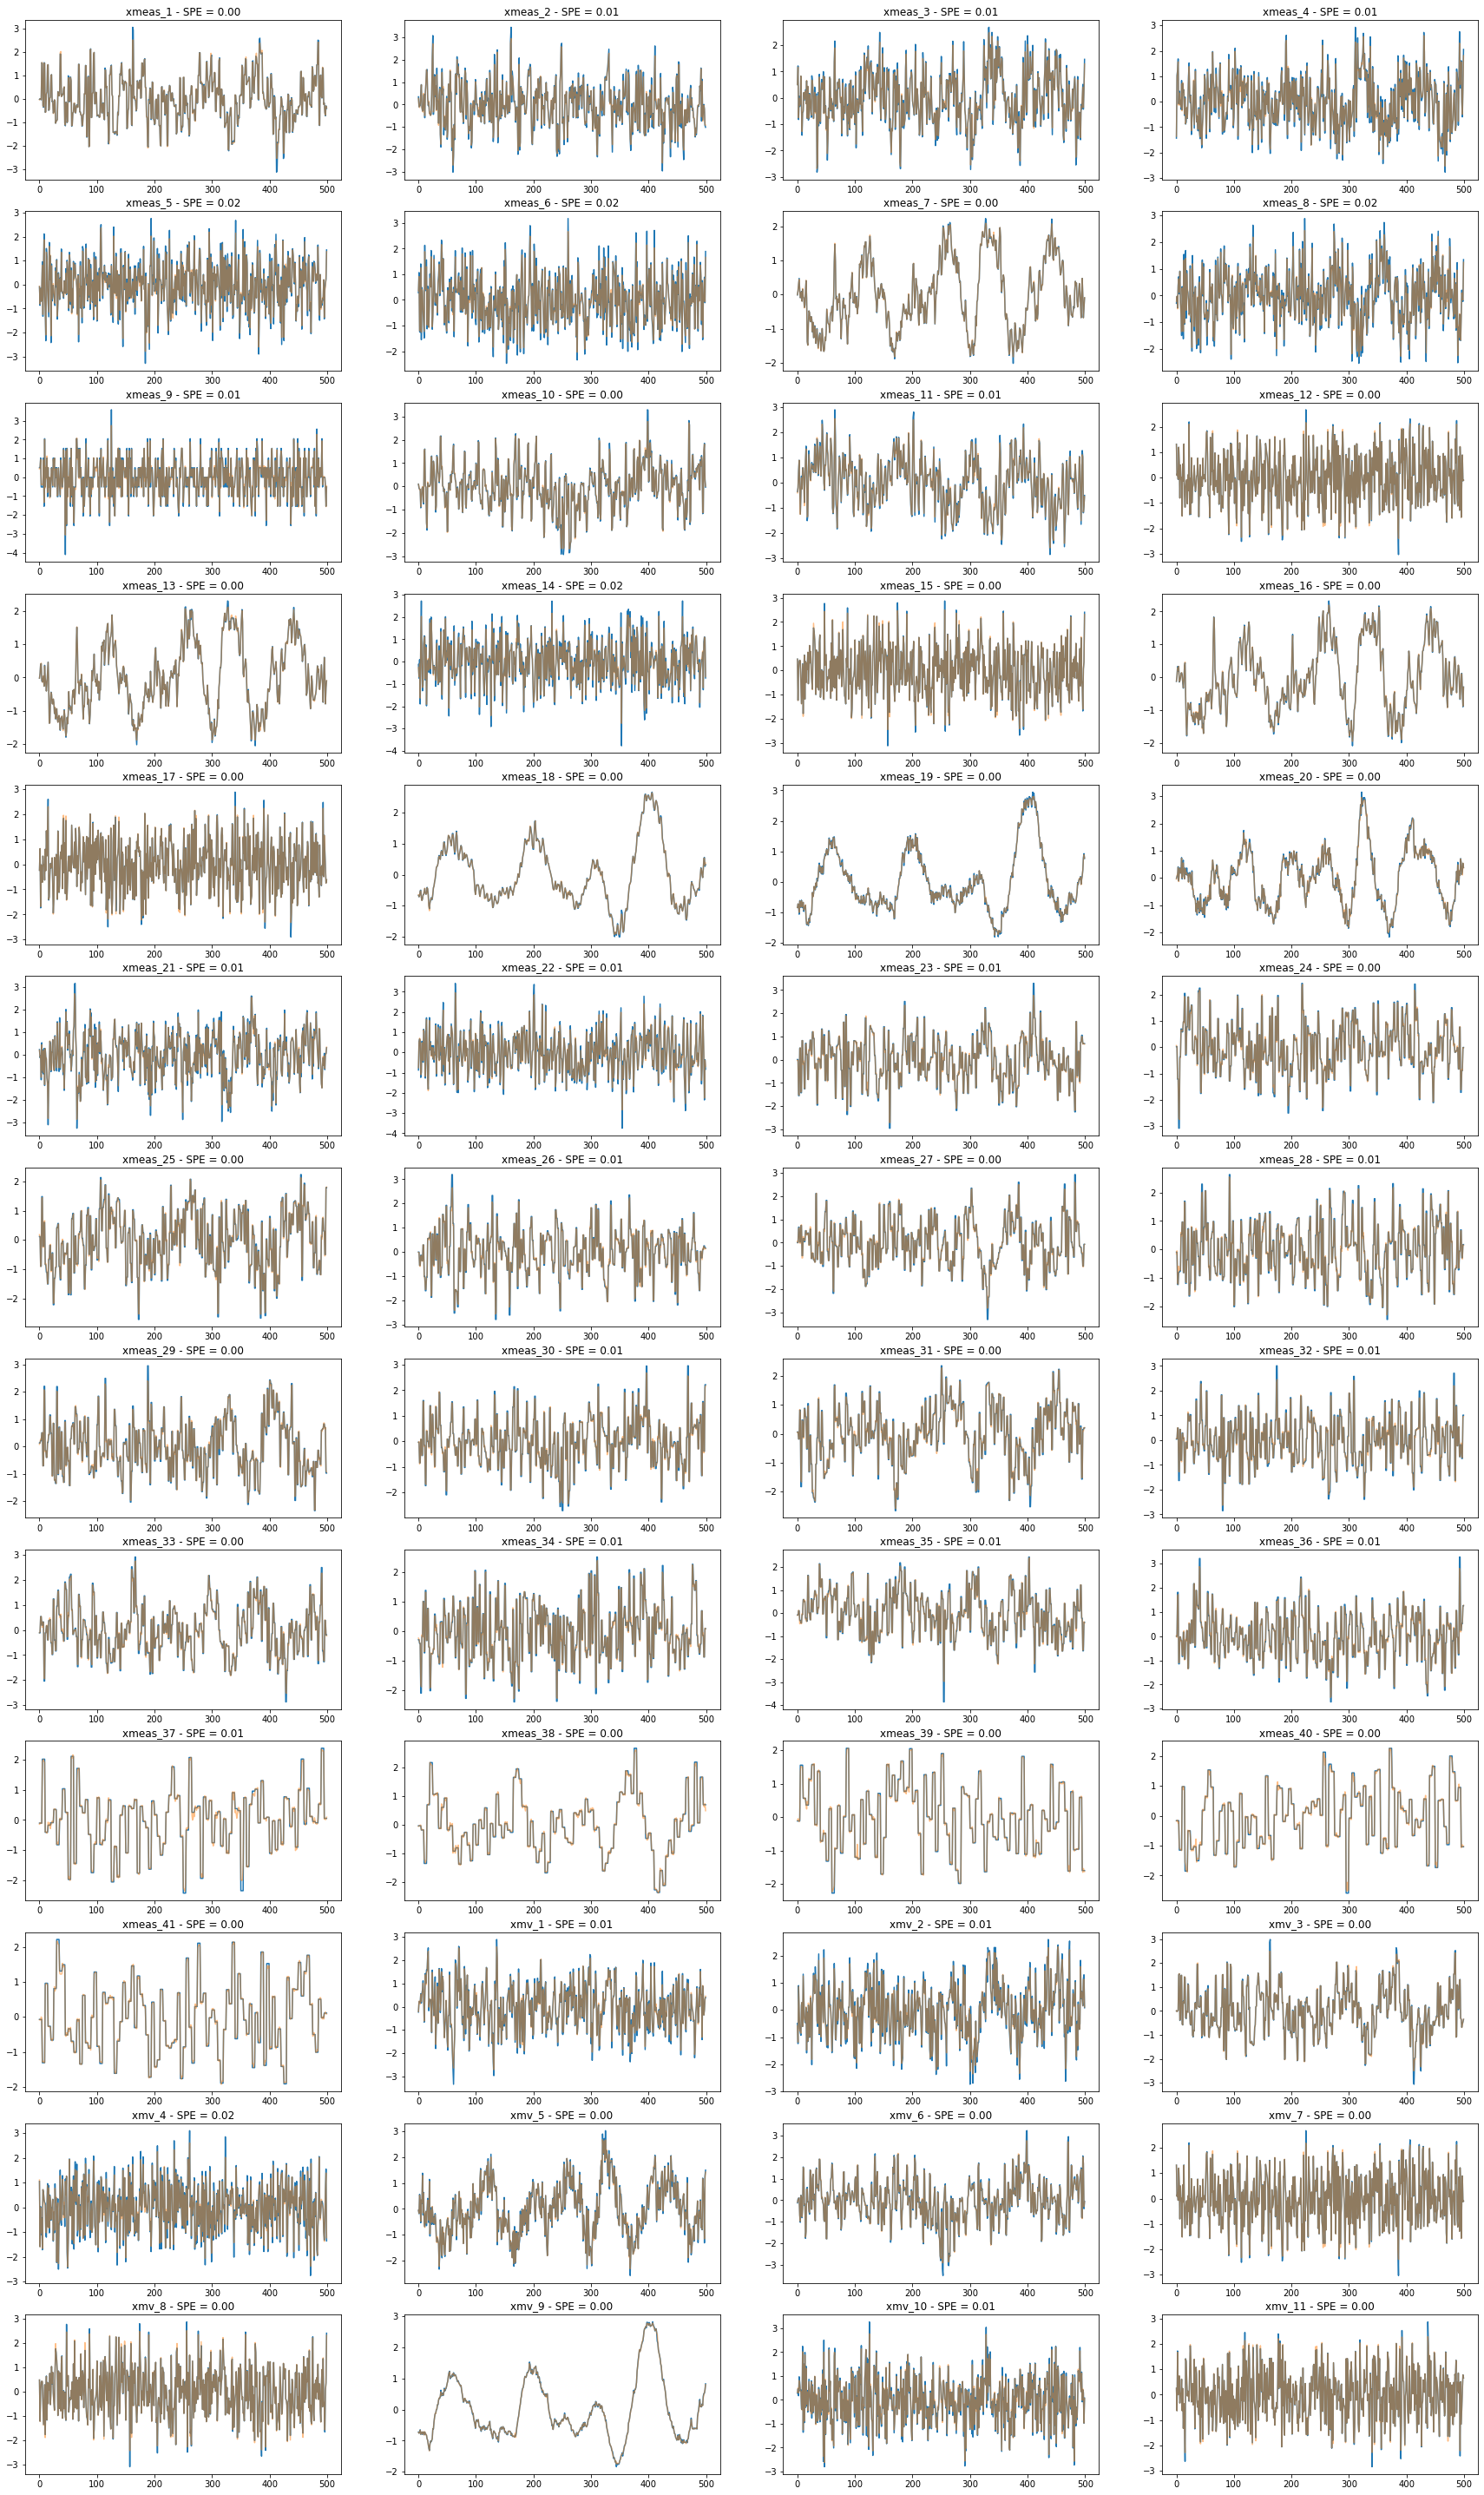

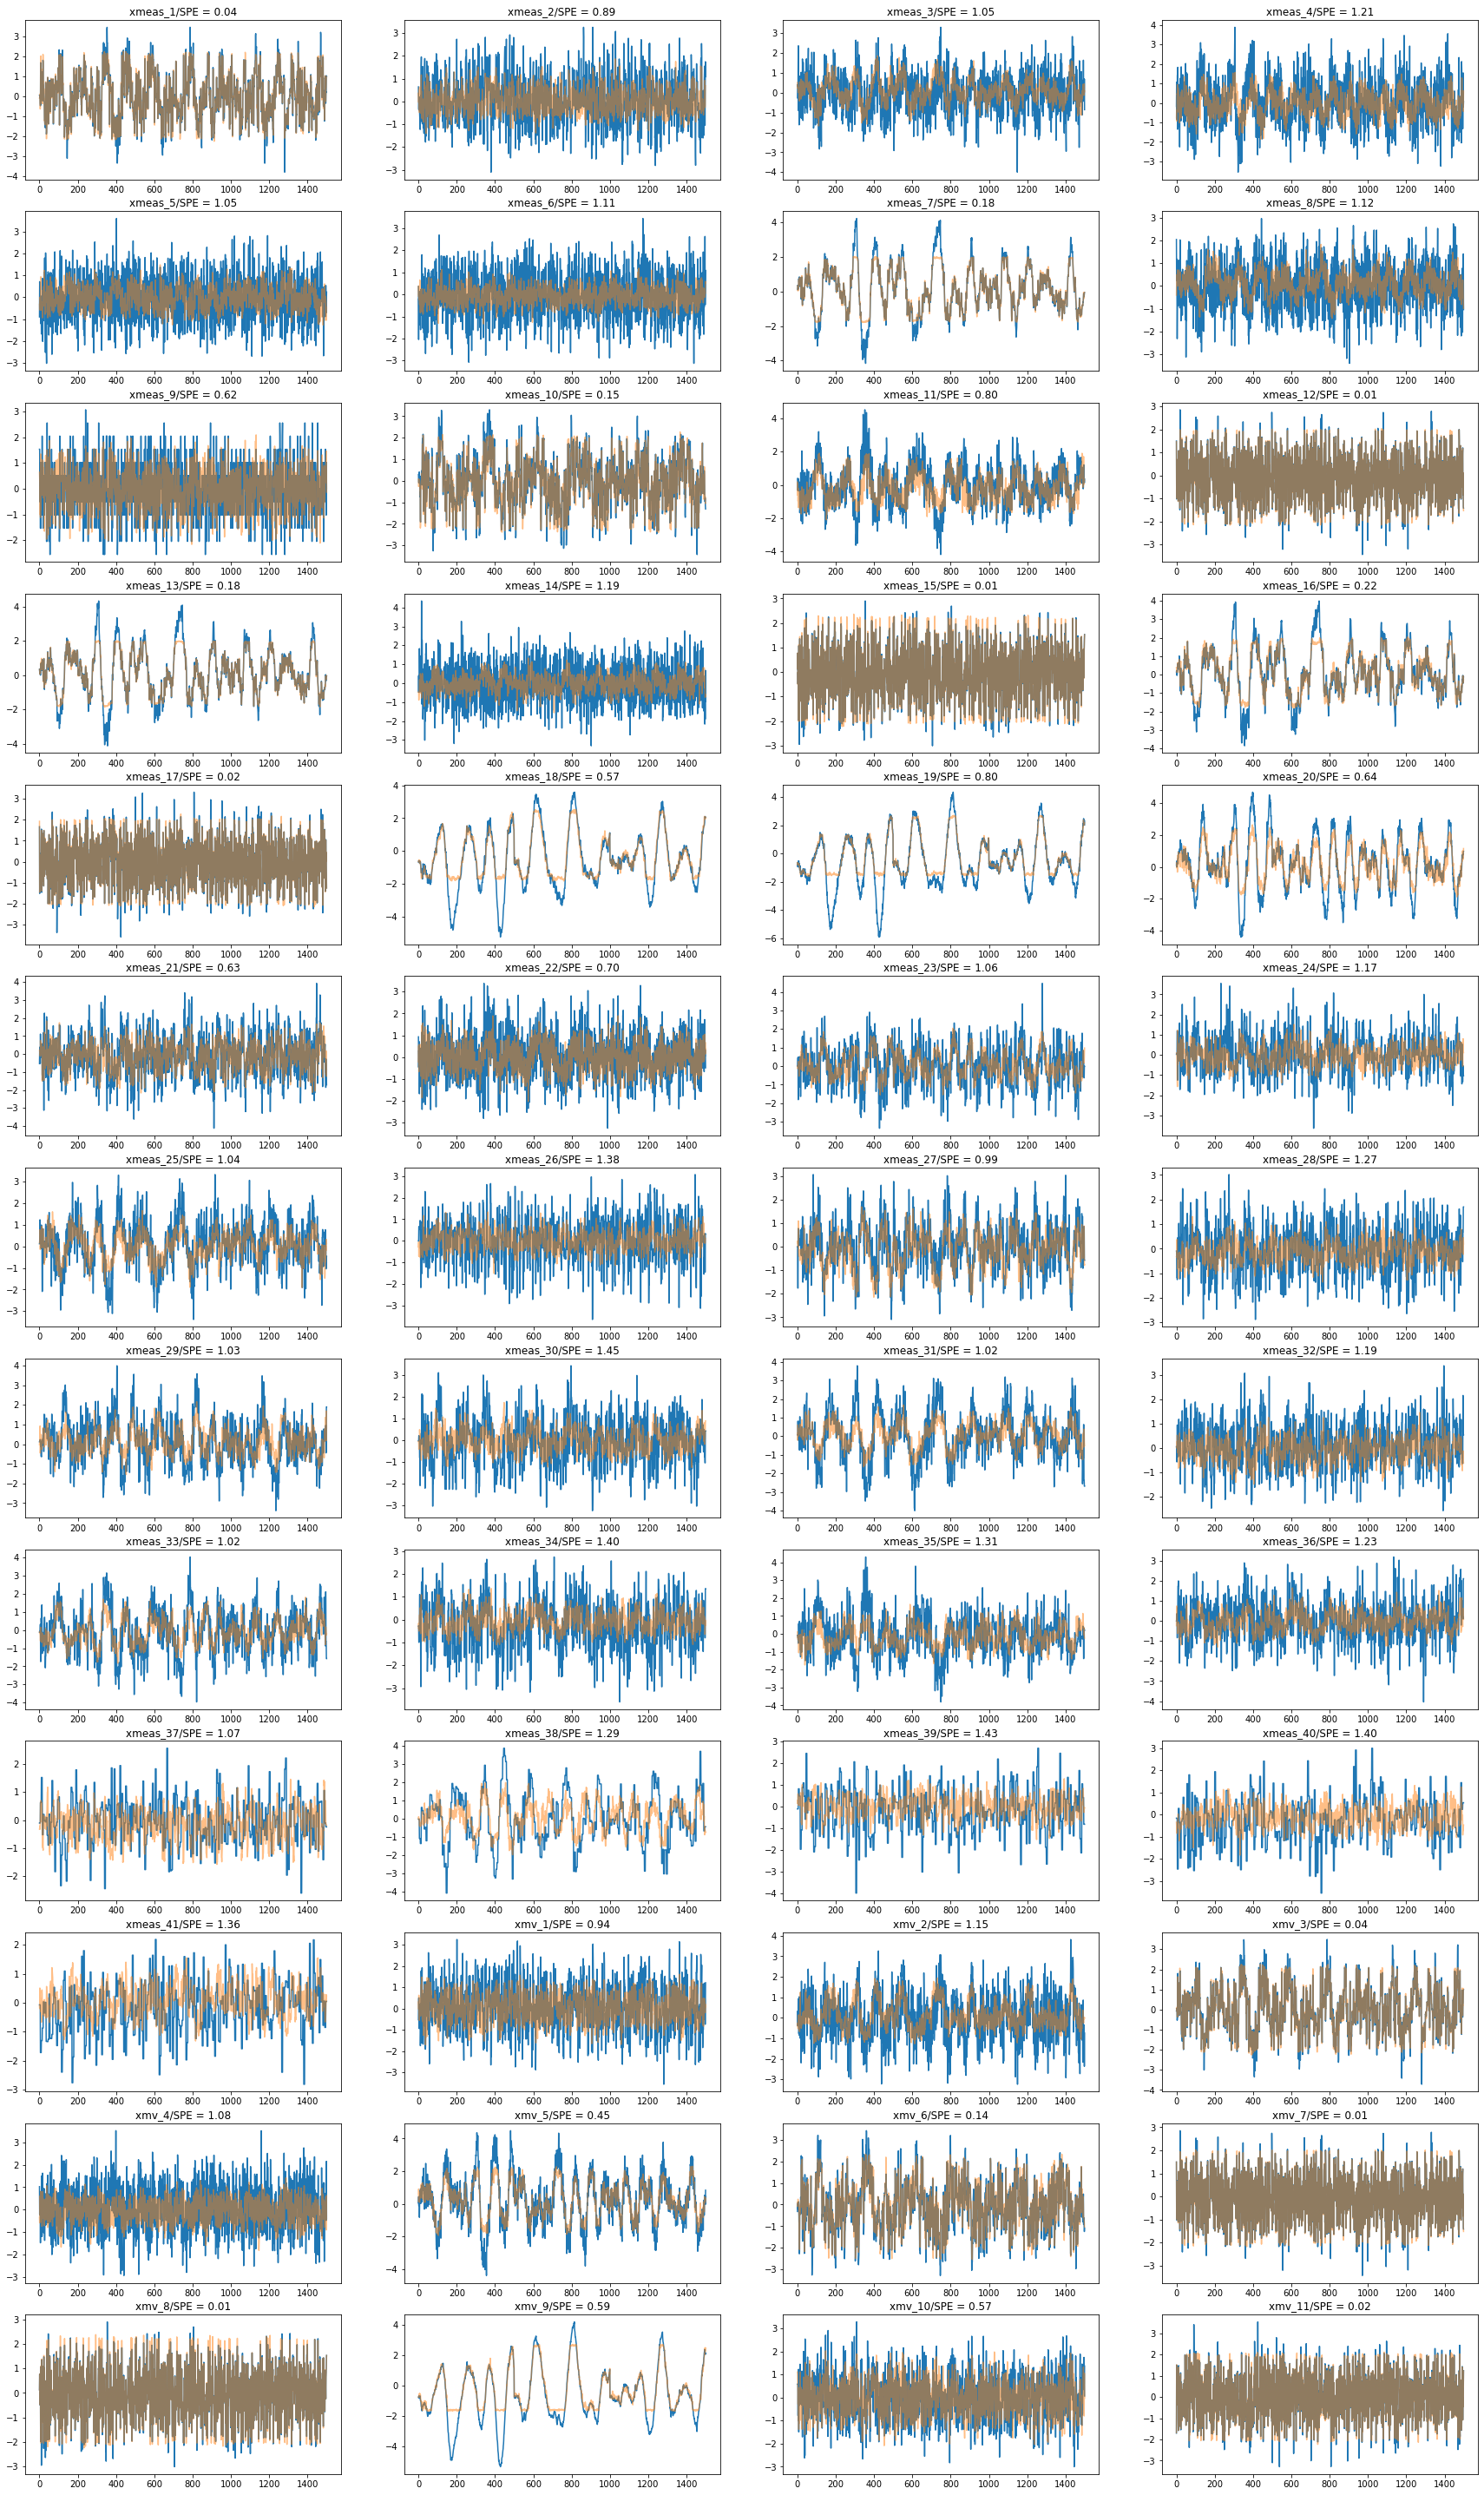

In [11]:
df_train = train_normal_complete[train_normal_complete.simulationRun==1].iloc[:,3:]
df_validation = train_normal_complete[(train_normal_complete.simulationRun>1)&(train_normal_complete.simulationRun<5)].iloc[:,3:]
df_test = train_normal_complete[(train_normal_complete.simulationRun>5)&(train_normal_complete.simulationRun<10)].iloc[:,3:]

reg = lgb.LGBMRegressor

models = {'pca': ModelPCA(), 'lgb': ModelEnsembleRegressors(reg)}
detection_limits = {}

fig, ax = plt.subplots(len(models),3, figsize=(20,4*len(models)))

i = 0

for name, model in models.items():
    
    spe_train = model.train(df_train, plot = True)
    spe_validation = model.test(df_validation, plot = True)
    spe_test = model.test(df_test)
    
    detection_limits[name] = np.percentile(spe_validation, 99.99)

    ax[i,0].plot(spe_train);
    ax[i,1].plot(spe_validation);
    ax[i,2].plot(spe_test);

    ax[i,0].set_title(f'Training - {name}')
    ax[i,1].set_title(f'Validation - {name}')
    ax[i,2].set_title(f'Test - {name}')

    ax[i,1].axhline(detection_limits[name], ls = '--')
    ax[i,2].axhline(detection_limits[name], ls = '--')
                  
    i+=1
    
fig.suptitle('SPE');

# Testing (faulty sets)

Here we have a comparison between PCA and LGB. We will print the overall fault detection rate and the results for each fault (tabularly and graphically).

pca    58.99375
lgb    53.25000
dtype: float64


,IDV(1),IDV(2),IDV(3),IDV(4),IDV(5),IDV(6),IDV(7),IDV(8),IDV(9),IDV(10),IDV(11),IDV(12),IDV(13),IDV(14),IDV(15),IDV(16),IDV(17),IDV(18),IDV(19),IDV(20)
pca,99.625,98.0,0.75,87.25,15.625,100.0,99.25,96.75,0.75,12.250,37.375,96.375,90.5,99.875,0.875,22.625,81.625,92.5,2.625,45.250
lgb,99.250,98.0,0.00,16.75,24.000,100.0,100.00,97.50,0.00,7.125,28.625,96.750,90.0,99.750,0.000,9.625,73.750,92.0,0.000,31.875


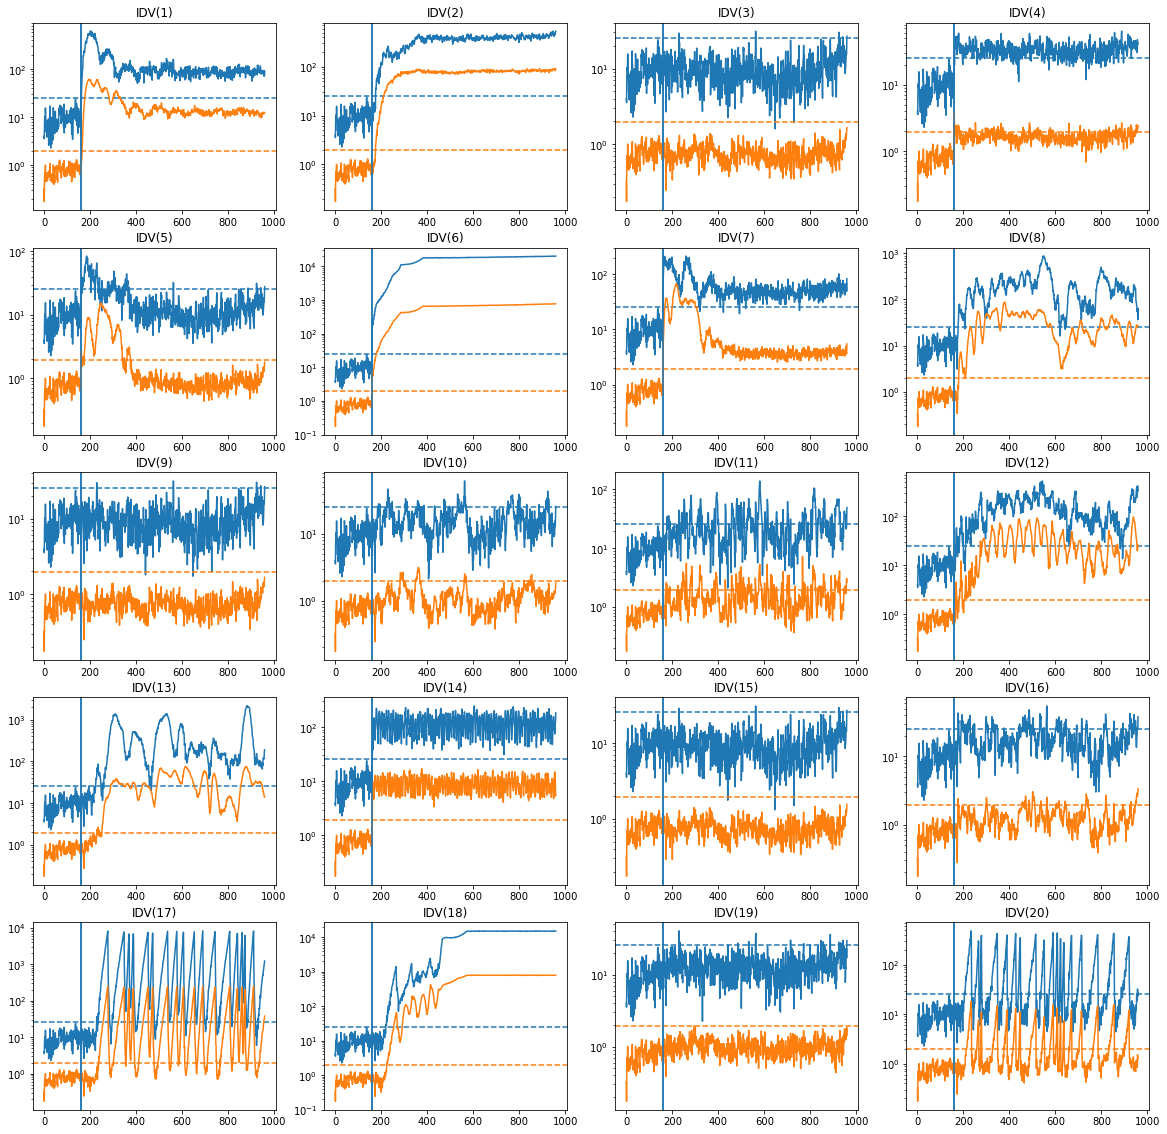

In [12]:
fig, ax = plt.subplots(5,4, figsize = (20, 20))

fdr_df = pd.DataFrame(index=[f'IDV({i})' for i in range(1,21)])

for name, model in models.items():

    spe_test = []
    fdr = []

    for i in range(20):

        df_test = test_faulty_complete[(test_faulty_complete.faultNumber==i+1) & (test_faulty_complete.simulationRun==1)].iloc[:,3:]

        spe_test.append(model.test(df_test))

        fault_occurrence = len(spe_test[i])//6

        fdr.append(np.mean(spe_test[i][fault_occurrence:]>detection_limits[name]))

        color = next(ax.ravel()[i]._get_lines.prop_cycler)['color']
        ax.ravel()[i].plot(np.arange(len(spe_test[i])), spe_test[i], color = color)
        ax.ravel()[i].axhline(detection_limits[name], ls='--', color = color)
        ax.ravel()[i].axvline(fault_occurrence)
        ax.ravel()[i].set_title(f'IDV({i+1})')
        ax.ravel()[i].set_yscale('log')
        
    fdr_df[name] = fdr
    
print(100*fdr_df.mean())    
100*fdr_df.T

The PCA model is superior.

# Adding lag variables

Here, this strategy will only be used with PCA (in this case, the technique is called Dynamical PCA, or DPCA).

pca_lag1    60.631250
pca_lag2    59.755945
pca_lag3    60.469925
dtype: float64


,IDV(1),IDV(2),IDV(3),IDV(4),IDV(5),IDV(6),IDV(7),IDV(8),IDV(9),IDV(10),IDV(11),IDV(12),IDV(13),IDV(14),IDV(15),IDV(16),IDV(17),IDV(18),IDV(19),IDV(20)
pca_lag1,99.625000,97.750000,0.0,100.0,9.875000,100.0,100.0,95.625000,0.0,13.250000,66.750000,95.750000,89.625000,97.500000,0.0,20.875000,84.250000,92.500000,3.250000,46.000000
pca_lag2,99.624531,97.747184,0.0,100.0,6.132666,100.0,100.0,95.744681,0.0,7.008761,66.207760,95.744681,90.237797,99.249061,0.0,14.392991,83.479349,92.490613,0.250313,46.808511
pca_lag3,99.749373,97.744361,0.0,100.0,6.892231,100.0,100.0,96.741855,0.0,8.145363,70.551378,97.117794,90.977444,100.000000,0.0,16.040100,84.210526,92.606516,0.250627,48.370927


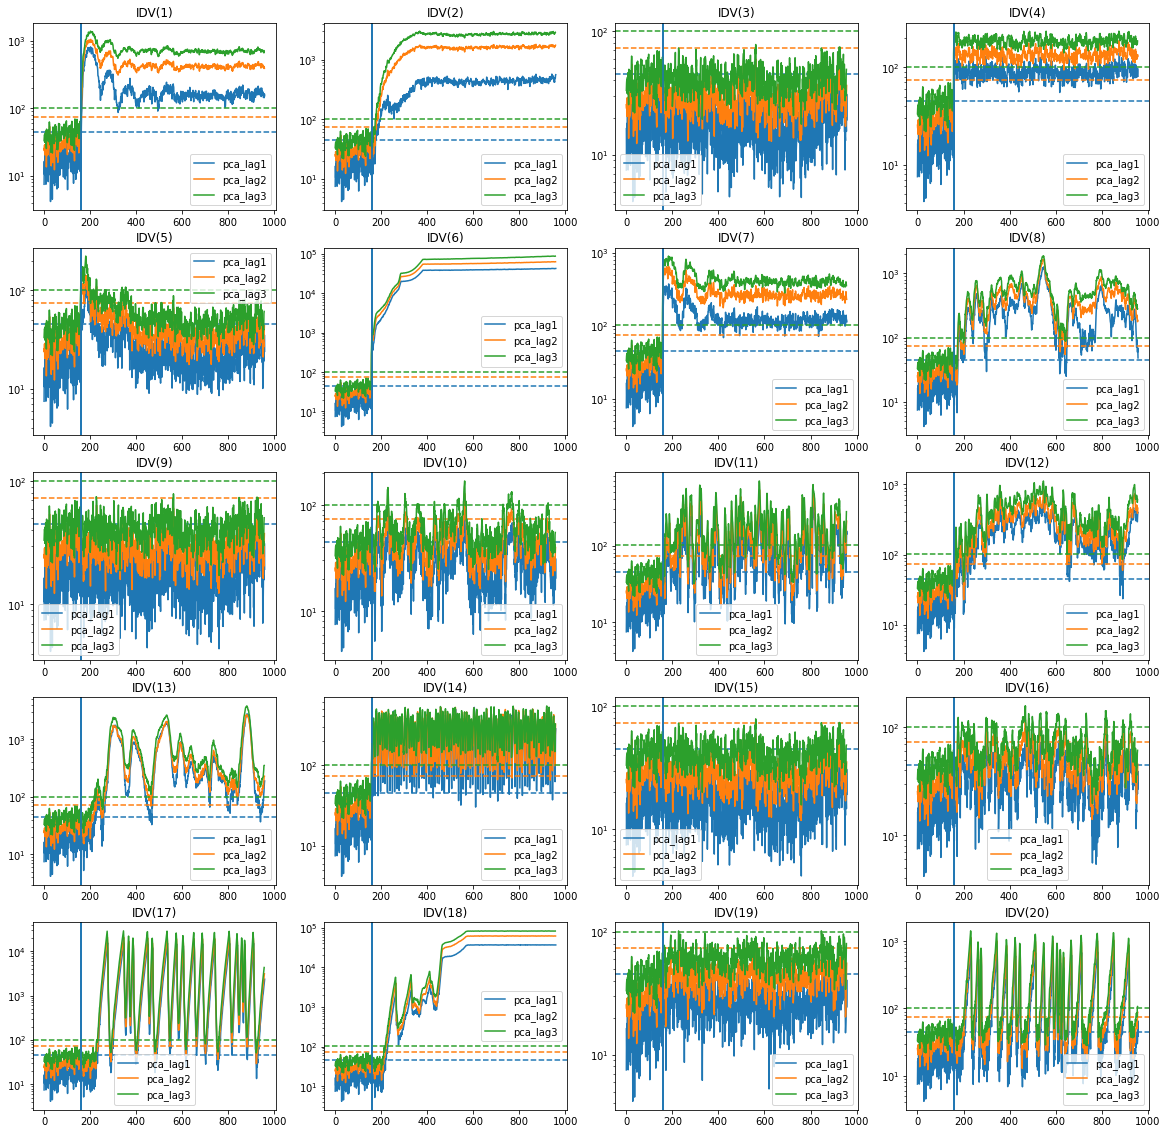

In [13]:
fig, ax = plt.subplots(5,4, figsize = (20, 20))

df_train = train_normal_complete[train_normal_complete.simulationRun==1].iloc[:,3:]
df_validation = train_normal_complete[(train_normal_complete.simulationRun>1)&(train_normal_complete.simulationRun<5)].iloc[:,3:]

models = {'pca_lag1': ModelPCA(), 'pca_lag2': ModelPCA(), 'pca_lag3': ModelPCA()}
lags = {'pca_lag1': 1, 'pca_lag2': 2, 'pca_lag3': 3}

detection_limits = {}

fdr_df = pd.DataFrame(index=[f'IDV({i})' for i in range(1,21)])

for name, model in models.items():

    spe_test = []
    fdr = []
    
    _ = model.train(apply_lag(df_train,lags[name]))
    spe_validation = model.test(apply_lag(df_validation,lags[name]))
    detection_limits[name] = np.percentile(spe_validation, 99.99)

    for i in range(20):
        
        df_test = apply_lag(test_faulty_complete[(test_faulty_complete.faultNumber==i+1) & 
                                                 (test_faulty_complete.simulationRun==1)].iloc[:,3:], lags[name])

        spe_test.append(model.test(df_test))

        fault_occurrence = len(spe_test[i])//6

        fdr.append(np.mean(spe_test[i][fault_occurrence:]>detection_limits[name]))

        color = next(ax.ravel()[i]._get_lines.prop_cycler)['color']
        ax.ravel()[i].plot(np.arange(len(spe_test[i])), spe_test[i], color = color, label=name)
        ax.ravel()[i].axhline(detection_limits[name], ls='--', color = color)
        ax.ravel()[i].axvline(fault_occurrence)
        ax.ravel()[i].set_title(f'IDV({i+1})')
        ax.ravel()[i].set_yscale('log')
        ax.ravel()[i].legend()
        
    fdr_df[name] = fdr
    
print(100*fdr_df.mean())
100*fdr_df.T

Although the overall performance does not increase, some cases benefit from the technique, especially the faults 11 and 14.

## Filtering noise

Three window sizes will be evaluated: 10, 50 and 100. 

### PCA

WS_10     59.700
WS_50     60.400
WS_100    59.775
dtype: float64


,IDV(1),IDV(2),IDV(3),IDV(4),IDV(5),IDV(6),IDV(7),IDV(8),IDV(9),IDV(10),IDV(11),IDV(12),IDV(13),IDV(14),IDV(15),IDV(16),IDV(17),IDV(18),IDV(19),IDV(20)
WS_10,99.250,98.125,0.0,99.75,46.625,99.875,99.750,97.375,0.0,6.125,80.000,98.500,94.25,35.375,0.0,3.25,90.125,92.875,0.500,52.250
WS_50,98.375,97.125,0.0,99.25,98.375,99.125,99.375,96.375,0.0,0.125,77.250,86.125,94.00,0.000,0.0,0.00,89.875,91.375,0.125,81.125
WS_100,98.250,96.125,0.0,98.75,97.125,98.875,99.000,94.375,0.0,0.000,64.625,83.750,93.00,0.000,0.0,0.00,89.750,90.250,0.125,91.500


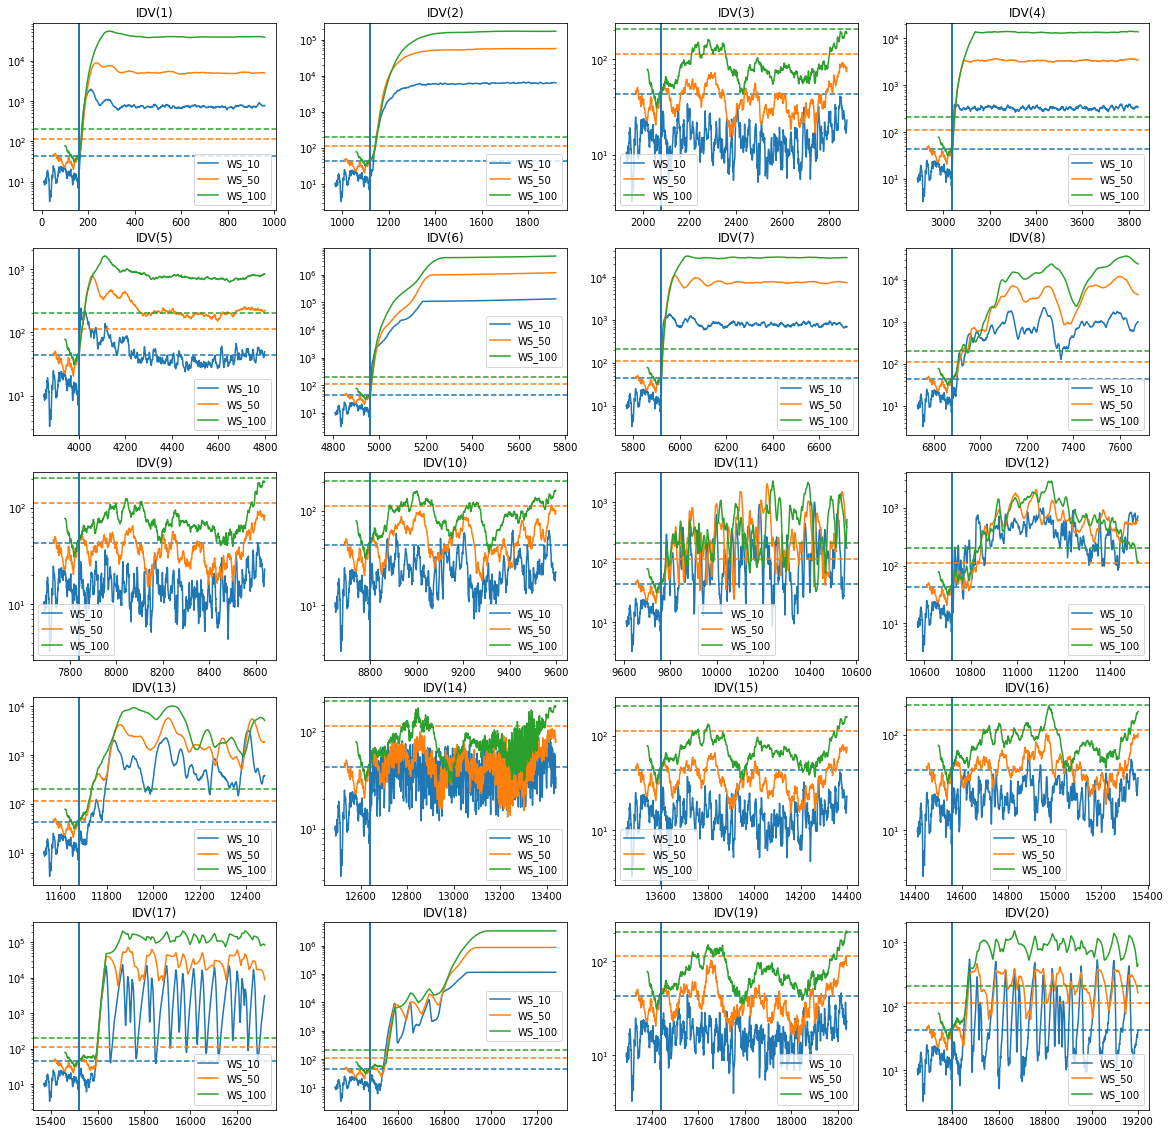

In [14]:
fig, ax = plt.subplots(5,4, figsize = (20, 20))

df_train = train_normal_complete[train_normal_complete.simulationRun==1].iloc[:,3:]
df_validation = train_normal_complete[(train_normal_complete.simulationRun>1)&(train_normal_complete.simulationRun<5)].iloc[:,3:]

models = {'WS_10': ModelPCA(), 'WS_50': ModelPCA(), 'WS_100': ModelPCA()}
WS = {'WS_10': 10, 'WS_50': 50, 'WS_100': 100}

detection_limits = {}

fdr_df = pd.DataFrame(index=[f'IDV({i})' for i in range(1,21)])

for name, model in models.items():

    spe_test = []
    fdr = []
    
    _ = model.train(filter_noise_ma(df_train,WS[name]))
    spe_validation = model.test(filter_noise_ma(df_validation, WS[name]))
    detection_limits[name] = np.percentile(spe_validation, 99.99)

    for i in range(20):
        
        df_test = filter_noise_ma(test_faulty_complete[(test_faulty_complete.faultNumber==i+1) & 
                                                 (test_faulty_complete.simulationRun==1)].iloc[:,3:], WS[name])

        spe_test.append(model.test(df_test))

        fault_occurrence = df_test.index[0]-WS[name]+160

        fdr.append(np.mean(spe_test[i][160-WS[name]:]>detection_limits[name]))

        color = next(ax.ravel()[i]._get_lines.prop_cycler)['color']
        ax.ravel()[i].plot(df_test.index, spe_test[i], color = color, label=name)
        ax.ravel()[i].axhline(detection_limits[name], ls='--', color = color)
        ax.ravel()[i].axvline(fault_occurrence)#, color = color)
        ax.ravel()[i].set_title(f'IDV({i+1})')
        ax.ravel()[i].set_yscale('log')
        ax.ravel()[i].legend()
        
    fdr_df[name] = fdr
    
print(100*fdr_df.mean())
100*fdr_df.T

### LGB

WS_10     55.40625
WS_50     58.79375
WS_100    59.04375
dtype: float64


,IDV(1),IDV(2),IDV(3),IDV(4),IDV(5),IDV(6),IDV(7),IDV(8),IDV(9),IDV(10),IDV(11),IDV(12),IDV(13),IDV(14),IDV(15),IDV(16),IDV(17),IDV(18),IDV(19),IDV(20)
WS_10,98.875,98.000,0.0,99.625,27.750,99.750,99.625,97.125,0.0,5.125,67.000,97.625,93.750,8.5,0.0,2.625,85.000,92.375,0.0,35.375
WS_50,98.250,96.625,0.0,98.875,97.625,99.000,99.250,95.125,0.0,2.125,67.250,84.750,93.125,0.0,0.0,0.000,89.625,90.875,0.0,63.375
WS_100,98.000,95.750,0.0,98.500,96.750,98.875,99.000,93.625,0.0,0.000,54.875,82.500,92.125,0.0,0.0,0.000,89.625,90.125,0.0,91.125


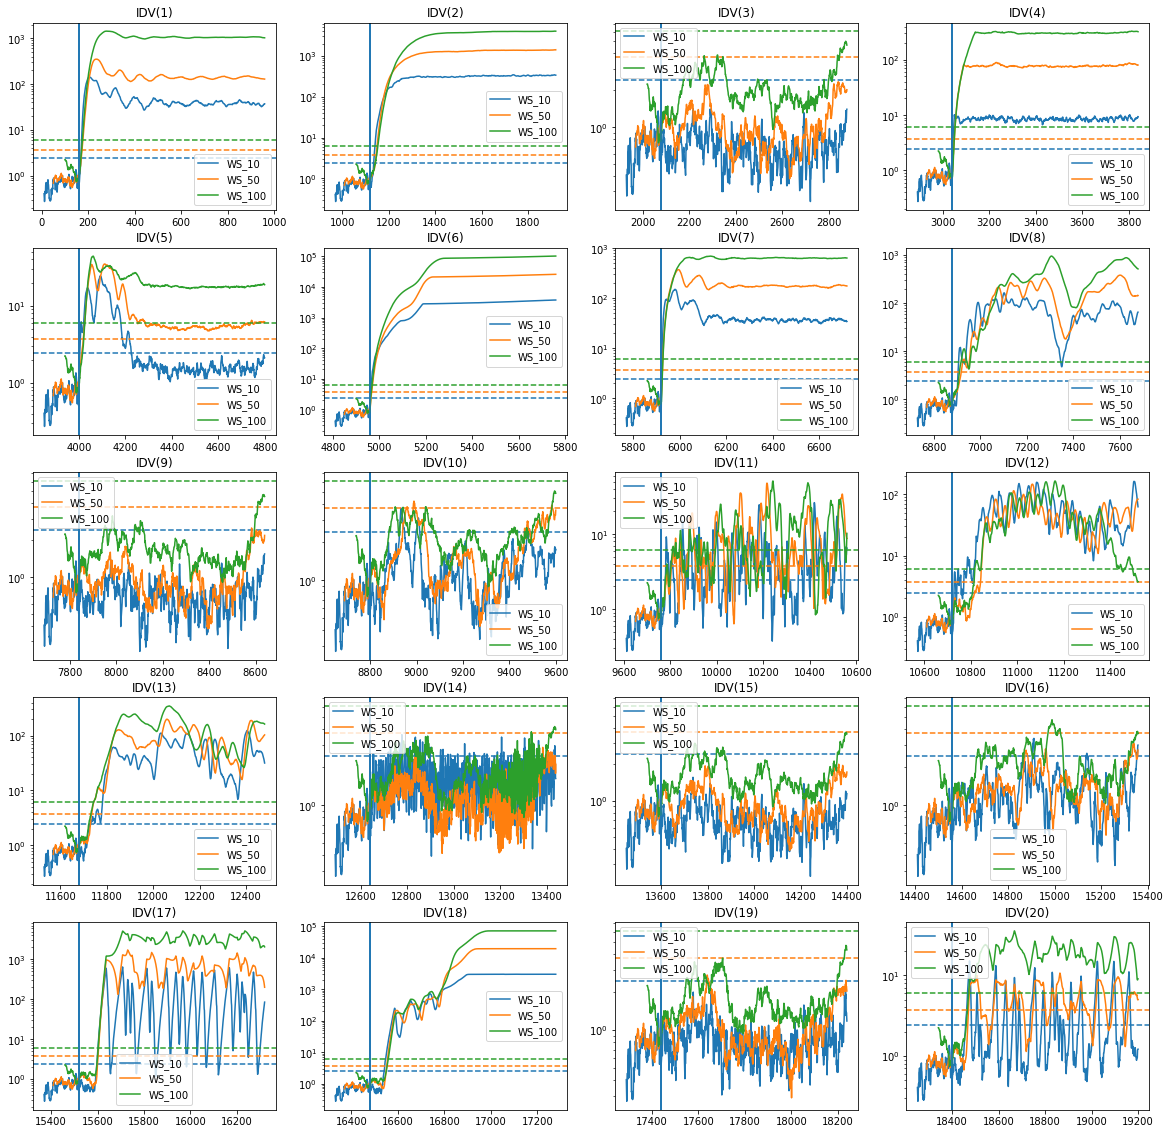

In [15]:
fig, ax = plt.subplots(5,4, figsize = (20, 20))

df_train = train_normal_complete[train_normal_complete.simulationRun==1].iloc[:,3:]
df_validation = train_normal_complete[(train_normal_complete.simulationRun>1)&(train_normal_complete.simulationRun<5)].iloc[:,3:]

reg = lgb.LGBMRegressor

models = {'WS_10': ModelEnsembleRegressors(reg), 'WS_50': ModelEnsembleRegressors(reg), 'WS_100': ModelEnsembleRegressors(reg)}
WS = {'WS_10': 10, 'WS_50': 50, 'WS_100': 100}

detection_limits = {}

fdr_df = pd.DataFrame(index=[f'IDV({i})' for i in range(1,21)])

for name, model in models.items():

    spe_test = []
    fdr = []
    
    _ = model.train(filter_noise_ma(df_train,WS[name]))
    spe_validation = model.test(filter_noise_ma(df_validation, WS[name]))
    detection_limits[name] = np.percentile(spe_validation, 99.99)

    for i in range(20):
        
        df_test = filter_noise_ma(test_faulty_complete[(test_faulty_complete.faultNumber==i+1) & 
                                                 (test_faulty_complete.simulationRun==1)].iloc[:,3:], WS[name])

        spe_test.append(model.test(df_test))

        fault_occurrence = df_test.index[0]-WS[name]+160

        fdr.append(np.mean(spe_test[i][160-WS[name]:]>detection_limits[name]))

        color = next(ax.ravel()[i]._get_lines.prop_cycler)['color']
        ax.ravel()[i].plot(df_test.index, spe_test[i], color = color, label=name)
        ax.ravel()[i].axhline(detection_limits[name], ls='--', color = color)
        ax.ravel()[i].axvline(fault_occurrence)#, color = color)
        ax.ravel()[i].set_title(f'IDV({i+1})')
        ax.ravel()[i].set_yscale('log')
        ax.ravel()[i].legend()
        
    fdr_df[name] = fdr
    
print(100*fdr_df.mean())
100*fdr_df.T

It is noticed that, in the global measure, the PCA model is not affected, although there is a significant improvement specifically in relation to faults 5 and 20.

Regarding the LGB model, there is an improvement in the overall performance that makes it reach fault detection rates similar to those of the PCA.

# Conclusions

* PCA and LGB can detect faults in Tennesse Eastman Processes.
* Some faults are easier to detect than others.
* In general, PCA is superior to LGB.
* Some faults are easier to detect when pre-processing techniques are applied.
* LGB benefits from noise filtering, achieving performances comparable to vanilla PCA.